# 01 · Análisis exploratorio de datos

**Proyecto:** clasificación multiclase del nivel de obesidad (`NObeyesdad`).

Este notebook describe el dataset, identifica tipos de variables, revisa faltantes y duplicados,
estudia la distribución de la variable objetivo y las asociaciones de cada predictor con ella.
También investiga el papel de `Weight` y `Height` en la construcción de la etiqueta.

> Todas las funciones están en `src/` (aquí solo se llaman y se interpretan sus resultados).
> Las figuras se guardan en `results/figures/` y las tablas en `results/tables/`.

In [1]:
import sys
from pathlib import Path

# Localiza la raíz del proyecto (carpeta que contiene src/) y la agrega al path
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from src import config as C
FIG = C.FIG_DIR
def show(name, width=900):
    display(Image(filename=str(FIG / name), width=width))

## 1. Carga de datos, dimensiones, faltantes y duplicados

In [2]:
from src import data, eda

df_raw = data.load_raw()
df = data.clean(df_raw)          # elimina duplicados exactos
info = eda.overview(df_raw)
info

{'filas': 2111,
 'columnas': 17,
 'valores_faltantes': 0,
 'filas_duplicadas': 24,
 'filas_tras_limpieza': 2087}

In [3]:
df_raw.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


El archivo tiene **2111 filas y 17 columnas**, **sin valores faltantes**, pero con **24 filas duplicadas**
exactas. Se eliminan antes de dividir los datos: si una copia quedara en entrenamiento y otra en prueba,
el modelo sería evaluado sobre un registro que ya “vio”, lo que inflaría la métrica de prueba.
Tras la limpieza quedan **2087 observaciones**.

## 2. Tipos de variables

In [4]:
eda.variable_table(df)

,variable,descripcion,tipo_pandas,tipo_estadistico,valores_unicos,faltantes
0,Gender,Género,str,Categórica nominal (binaria),2,0
1,Age,Edad (años),float64,Numérica,1402,0
2,Height,Estatura (m),float64,Numérica,1574,0
3,Weight,Peso (kg),float64,Numérica,1525,0
4,family_history_with_overweight,Antecedente familiar de sobrepeso,str,Categórica nominal (binaria),2,0
5,FAVC,Consumo frecuente de alimentos hipercalóricos,str,Categórica nominal (binaria),2,0
6,FCVC,Frecuencia de consumo de verduras (1-3),float64,Numérica,810,0
7,NCP,Número de comidas principales al día (1-4),float64,Numérica,635,0
8,CAEC,Consumo de alimentos entre comidas,str,Categórica ordinal,4,0
9,SMOKE,Fuma,str,Categórica nominal (binaria),2,0


- **Numéricas (8):** `Age`, `Height`, `Weight`, `FCVC`, `NCP`, `CH2O`, `FAF`, `TUE`.
- **Categóricas ordinales (2):** `CAEC` y `CALC` (no < Sometimes < Frequently < Always).
- **Categóricas nominales (6):** `Gender`, `family_history_with_overweight`, `FAVC`, `SMOKE`, `SCC` (binarias) y `MTRANS` (5 niveles).
- **Objetivo:** `NObeyesdad`, 7 clases con orden natural (de peso insuficiente a obesidad tipo III).

`FCVC`, `NCP`, `CH2O`, `FAF` y `TUE` son respuestas de encuesta en escala entera, pero entre el 31 % y el 62 %
de sus valores no son enteros. Es una huella del origen **sintético** de la mayor parte del dataset (77 %
de los registros se generó con SMOTE, según sus autores). Se tratan como numéricas continuas.

In [5]:
for c in C.NUMERIC_FEATURES:
    print(f"{c:<5} valores no enteros: {100 * (df[c] % 1 != 0).mean():5.1f} %")

Age   valores no enteros:  65.9 %
FCVC  valores no enteros:  39.6 %
NCP   valores no enteros:  30.7 %
CH2O  valores no enteros:  61.8 %
FAF   valores no enteros:  57.9 %
TUE   valores no enteros:  55.2 %


## 3. Estadísticos descriptivos

In [6]:
eda.numeric_descriptives(df)

,count,mean,std,min,25%,50%,75%,max,asimetria,curtosis
Age,2087.0,24.353,6.369,14.00,19.916,22.848,26.000,61.00,1.514,2.768
Height,2087.0,1.703,0.093,1.45,1.630,1.702,1.769,1.98,-0.025,-0.556
Weight,2087.0,86.859,26.191,39.00,66.000,83.101,108.016,173.00,0.242,-0.705
FCVC,2087.0,2.421,0.535,1.00,2.000,2.396,3.000,3.00,-0.448,-0.624
NCP,2087.0,2.701,0.765,1.00,2.697,3.000,3.000,4.00,-1.138,0.535
CH2O,2087.0,2.005,0.608,1.00,1.591,2.000,2.466,3.00,-0.106,-0.864
FAF,2087.0,1.013,0.853,0.00,0.125,1.000,1.678,3.00,0.494,-0.638
TUE,2087.0,0.663,0.608,0.00,0.000,0.631,1.000,2.00,0.609,-0.554


In [7]:
eda.categorical_frequencies(df).query("variable != @C.TARGET")

,variable,nivel,n,porcentaje
0,Gender,Male,1052,50.41
1,Gender,Female,1035,49.59
2,family_history_with_overweight,yes,1722,82.51
3,family_history_with_overweight,no,365,17.49
4,FAVC,yes,1844,88.36
5,FAVC,no,243,11.64
6,CAEC,Sometimes,1761,84.38
7,CAEC,Frequently,236,11.31
8,CAEC,Always,53,2.54
9,CAEC,no,37,1.77


Varias categóricas están muy desbalanceadas: `SMOKE = yes` (2 %), `SCC = yes` (5 %), `CALC = Always`
(1 registro) y `MTRANS = Bike/Motorbike` (< 1 %). Estas categorías raras aportan poca información y
pueden no aparecer en algunos folds; por eso el codificador One-Hot usa `handle_unknown="ignore"`.

## 4. Distribución de la variable objetivo

,n,porcentaje
NObeyesdad,,
Insufficient_Weight,267,12.79
Normal_Weight,282,13.51
Overweight_Level_I,276,13.22
Overweight_Level_II,290,13.90
Obesity_Type_I,351,16.82
Obesity_Type_II,297,14.23
Obesity_Type_III,324,15.52


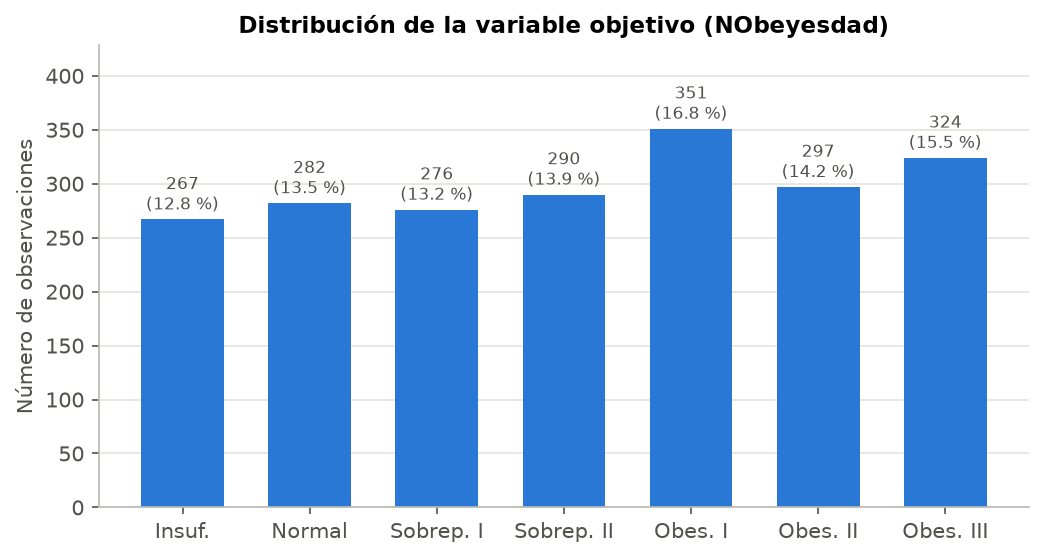

In [8]:
display(eda.target_distribution(df))
eda.plot_target(df); show("01_distribucion_objetivo.png", 750)

Las 7 clases están **aproximadamente balanceadas** (entre 12,8 % y 16,8 %). Aun así se usa una
**división estratificada** para conservar exactamente estas proporciones en entrenamiento y prueba, y
métricas con **promedio macro**, que dan el mismo peso a todas las clases.

## 5. Distribuciones de las variables numéricas

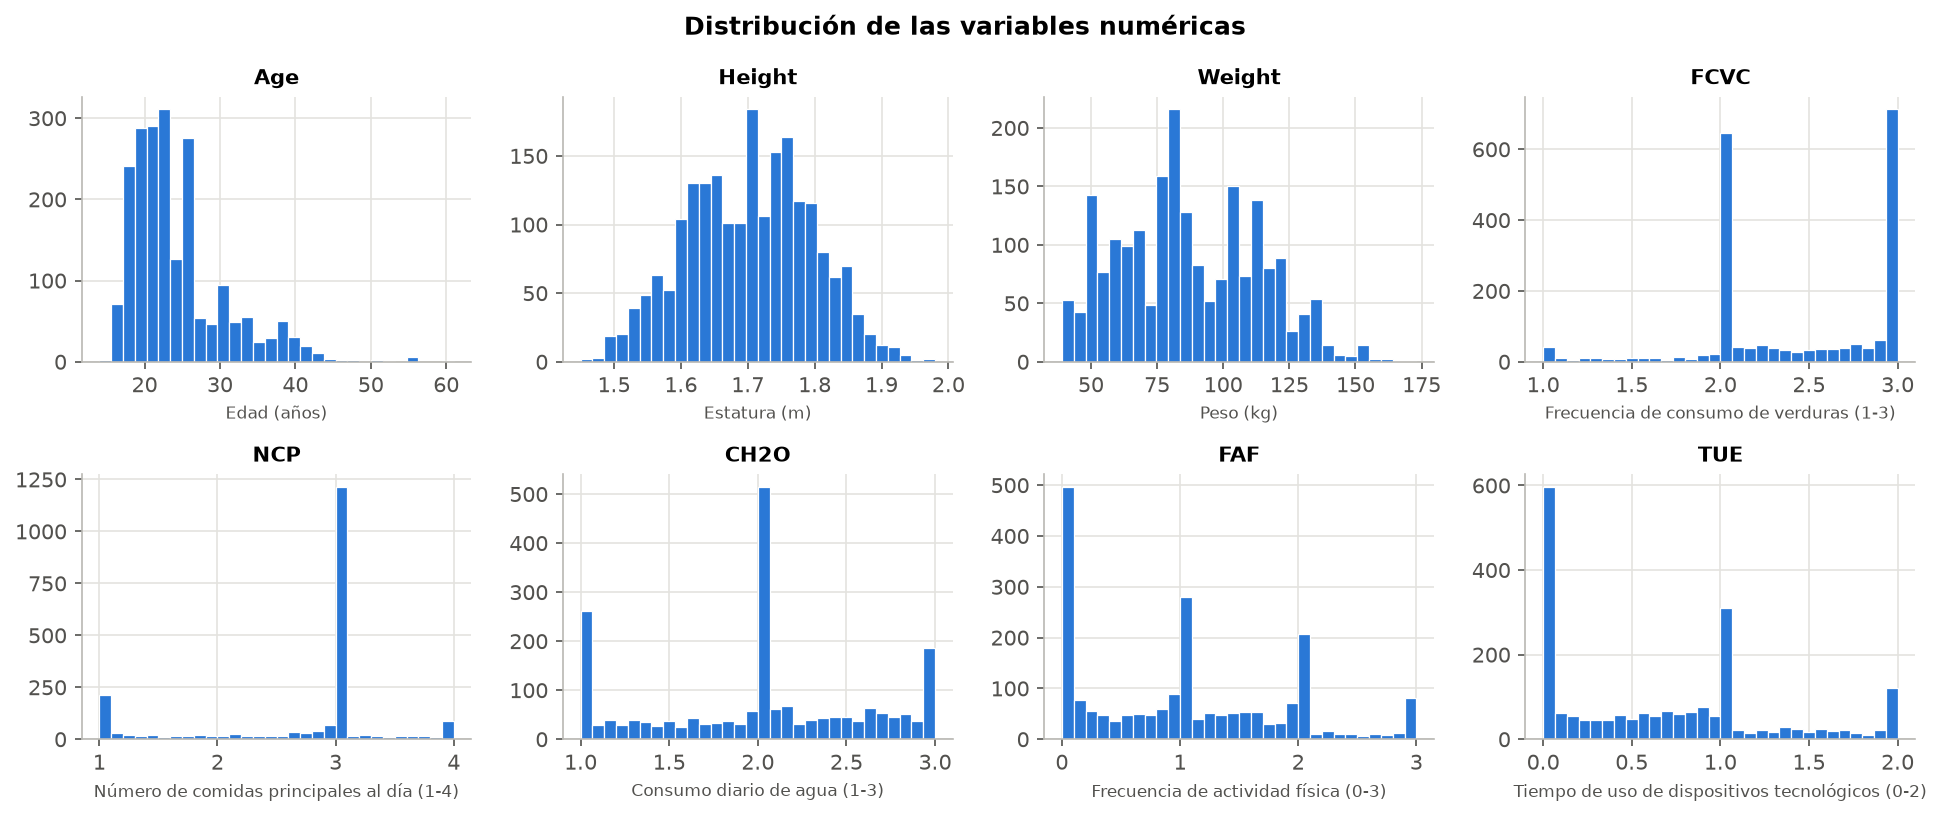

In [9]:
eda.plot_numeric_histograms(df); show("02_histogramas_numericas.png")

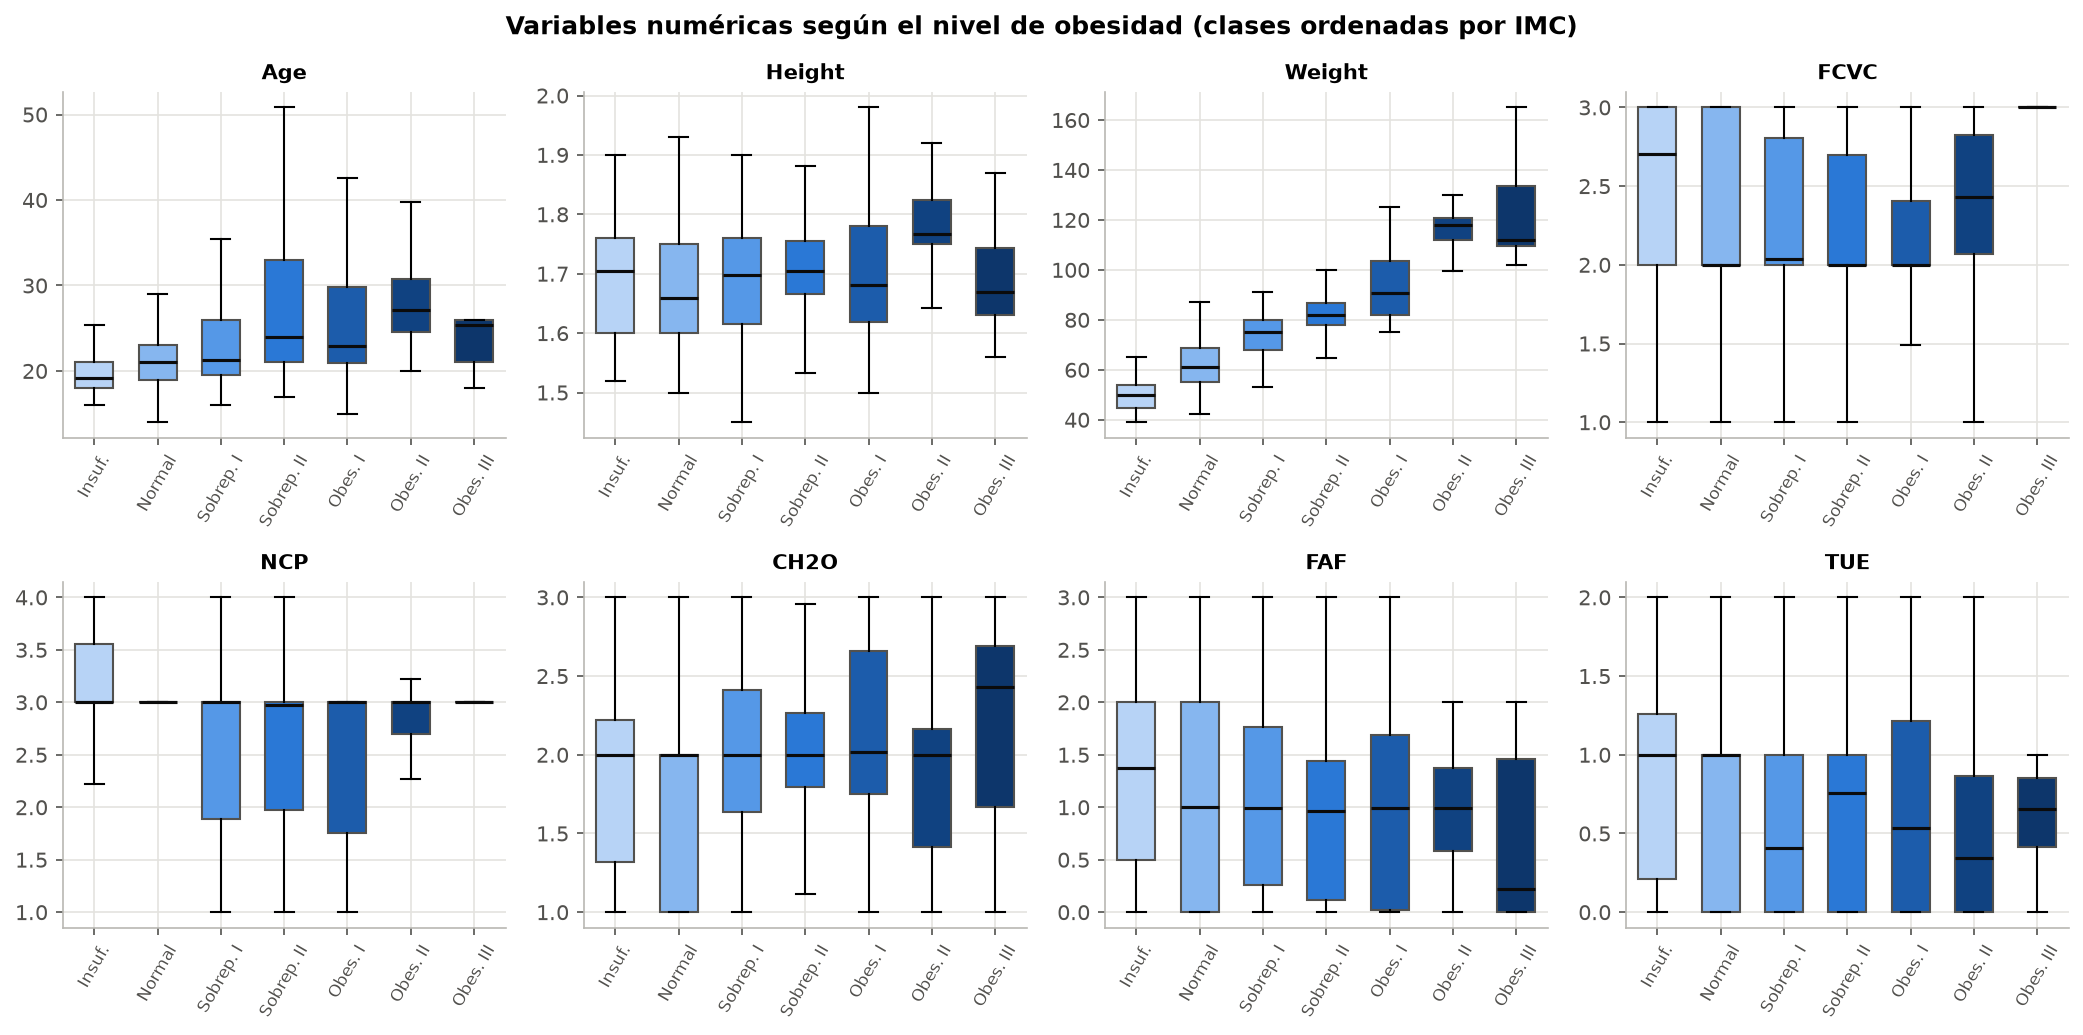

In [10]:
eda.plot_numeric_by_class(df); show("03_boxplots_por_clase.png")

`Weight` crece de forma casi monótona con el nivel de obesidad, mientras que `Height` cambia poco entre
clases. Entre las variables de hábitos, `FCVC` (consumo de verduras) y `Age` muestran diferencias
claras; `FAF`, `CH2O` y `TUE` muestran diferencias más pequeñas.

## 6. Correlaciones y asociaciones con la variable objetivo

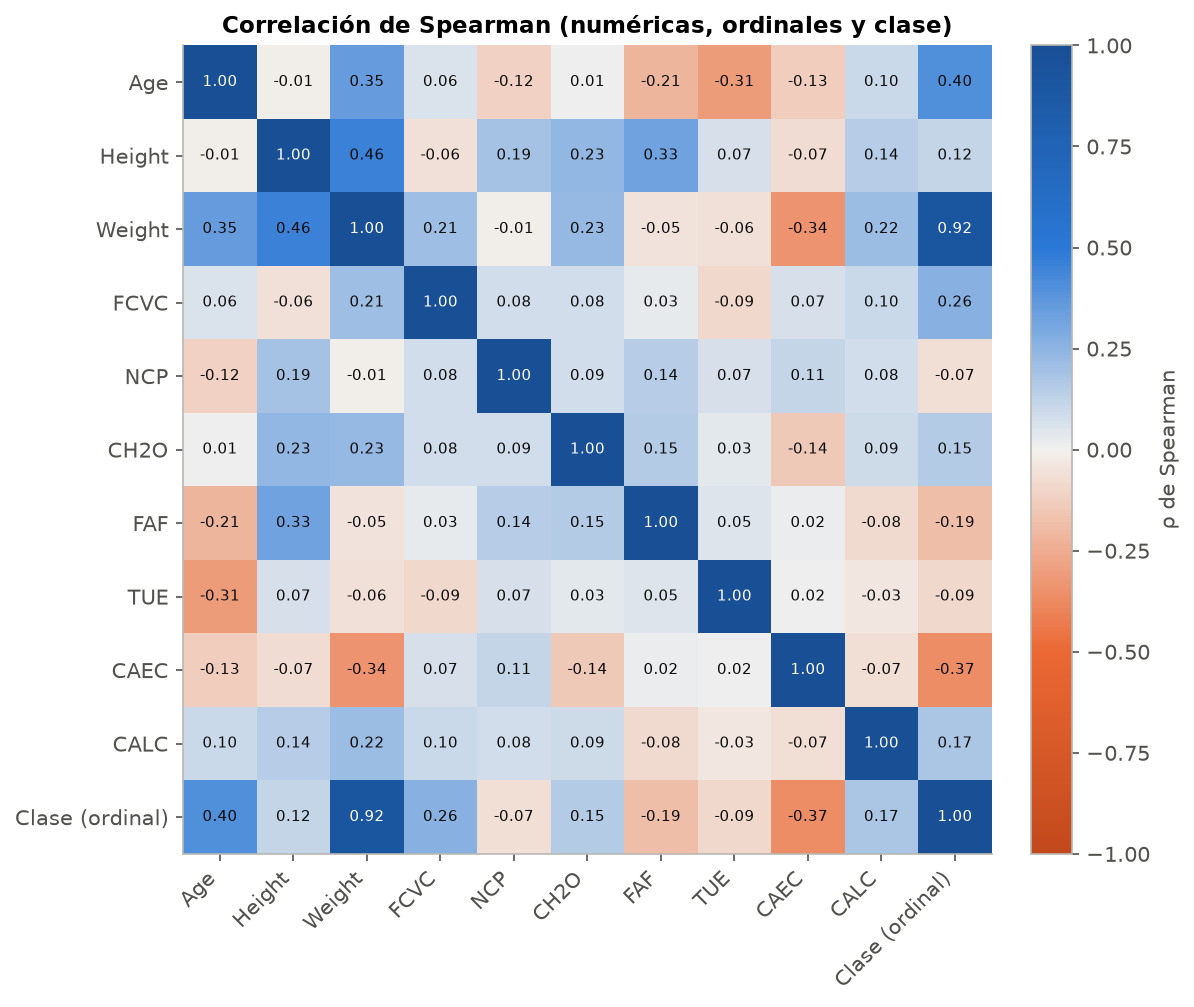

In [11]:
eda.plot_correlation(df); show("04_correlacion_spearman.png", 700)

Se usa la correlación de **Spearman** (por rangos) porque varias variables son ordinales o no normales.
La clase, codificada de 0 a 6, tiene correlación muy alta con `Weight` (ρ = 0,92) y débil con `Height`
(ρ = 0,12). Entre las variables de hábitos, las más correlacionadas con la clase son `Age` (0,40), `CAEC`
(−0,37) y `FCVC` (0,26). El signo negativo de `CAEC` es contraintuitivo: las personas con obesidad
responden mayoritariamente “Sometimes”, mientras que “Frequently” aparece sobre todo en peso normal o
insuficiente. Entre los predictores, todas las correlaciones cumplen |ρ| ≤ 0,46 (la mayor es
Height–Weight), así que la multicolinealidad no es un problema relevante.

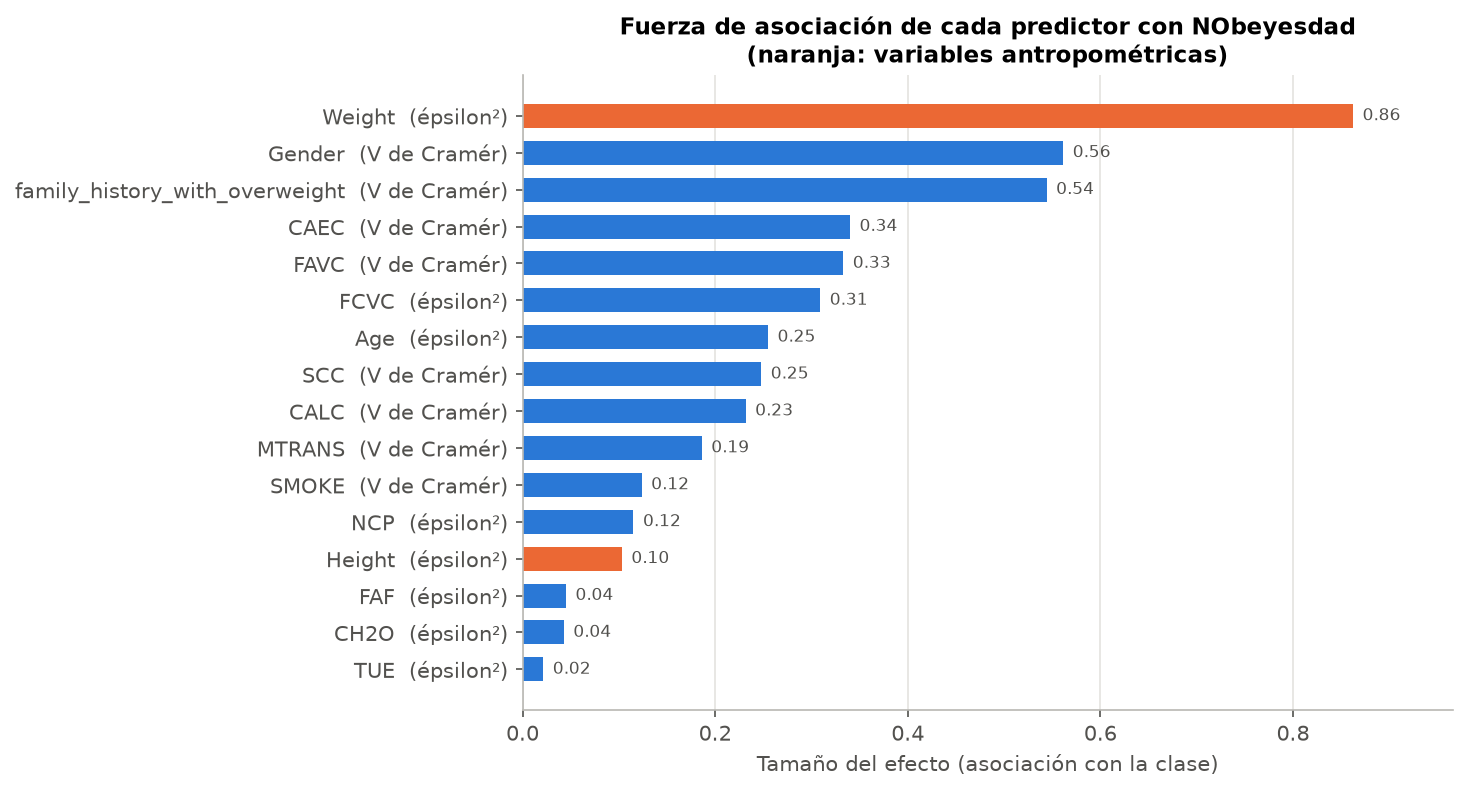

,variable,tipo,prueba,estadistico,p_valor,tamano_efecto,medida_efecto,pct_celdas_esperado_menor_5
0,Weight,Numérica,Kruskal-Wallis,1798.601282,0.000000e+00,0.862225,épsilon²,NaN
1,Gender,Categórica,Chi-cuadrado,657.452978,9.357968e-139,0.561269,V de Cramér,0.0
2,family_history_with_overweight,Categórica,Chi-cuadrado,617.710993,3.524156e-130,0.544041,V de Cramér,0.0
3,CAEC,Categórica,Chi-cuadrado,723.339781,6.301258e-142,0.339899,V de Cramér,10.7
4,FAVC,Categórica,Chi-cuadrado,231.276208,4.089708e-47,0.332893,V de Cramér,0.0
5,FCVC,Numérica,Kruskal-Wallis,644.495394,5.856638e-136,0.308962,épsilon²,NaN
6,Age,Numérica,Kruskal-Wallis,531.438551,1.414718e-111,0.254764,épsilon²,NaN
7,SCC,Categórica,Chi-cuadrado,128.030882,3.338513e-25,0.247683,V de Cramér,0.0
8,CALC,Categórica,Chi-cuadrado,335.564929,2.220940e-60,0.231508,V de Cramér,25.0
9,MTRANS,Categórica,Chi-cuadrado,288.567857,3.331989e-47,0.185923,V de Cramér,40.0


In [12]:
assoc = eda.target_associations(df)
eda.plot_associations(assoc); show("05_asociacion_objetivo.png", 750)
assoc

**Pruebas utilizadas**

- Numéricas vs. clase: **Kruskal-Wallis** (no supone normalidad), con tamaño de efecto
  $\varepsilon^2 = H/(n-1)$.
- Categóricas vs. clase: **chi-cuadrado de independencia**, con tamaño de efecto **V de Cramér**.

Con n = 2087 todas las pruebas son significativas (p < 0,001), así que lo informativo es el **tamaño del
efecto**. `Weight` domina ($\varepsilon^2$ = 0,86). Entre los predictores no antropométricos destacan `Gender`
(V = 0,56), `family_history_with_overweight` (V = 0,54), `CAEC`, `FAVC` y `FCVC`. En `CALC` y `MTRANS`,
el 25–40 % de las celdas tiene frecuencia esperada < 5, por lo que su p-valor chi-cuadrado es solo aproximado.

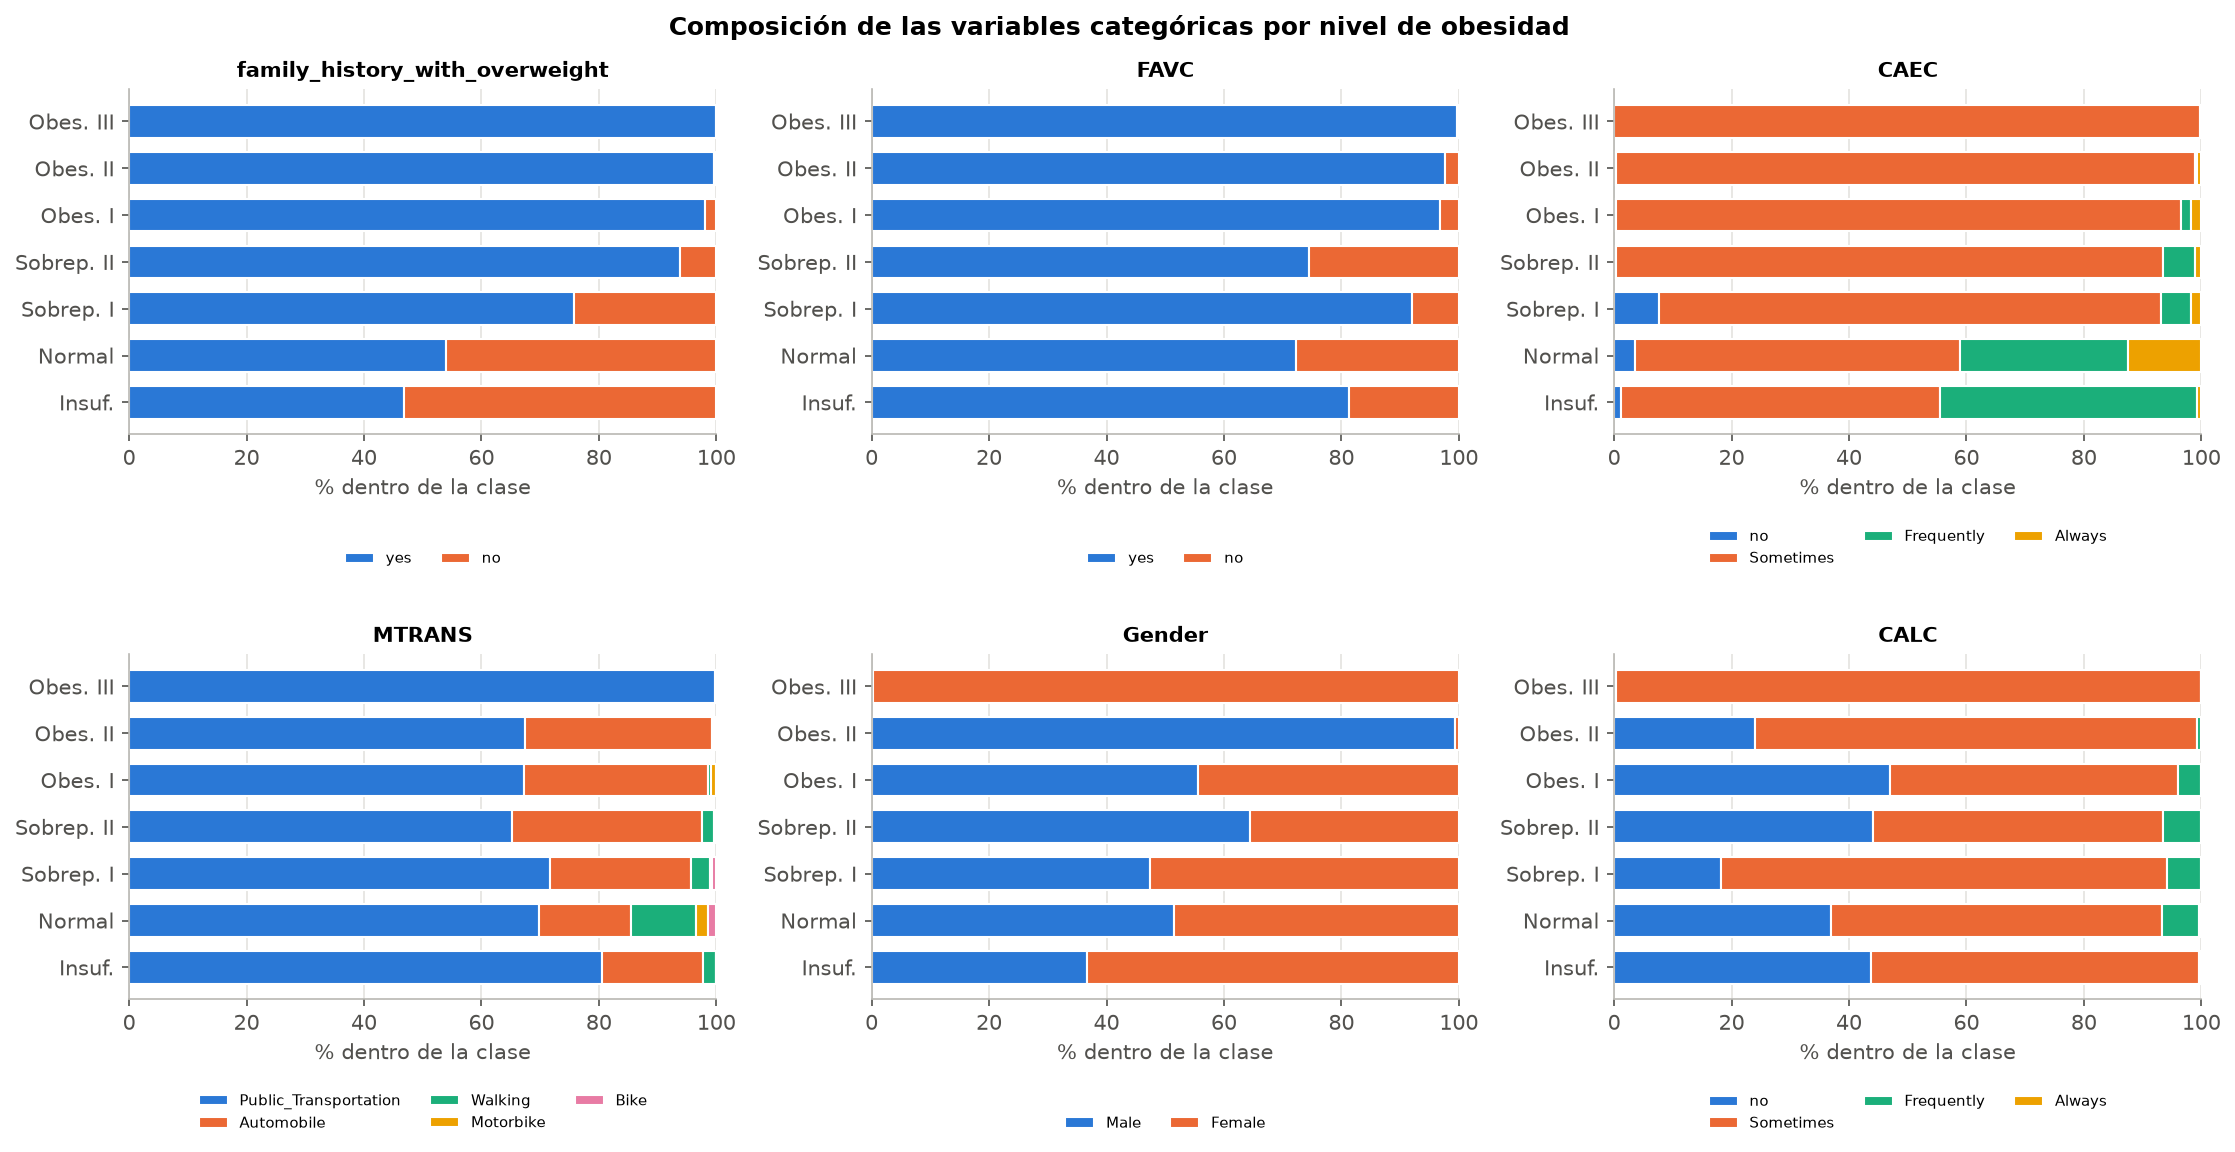

In [13]:
eda.plot_categorical_by_class(df); show("06_categoricas_por_clase.png")

In [14]:
pd.crosstab(df[C.TARGET], df["Gender"]).reindex(C.CLASS_ORDER)

Gender,Female,Male
NObeyesdad,,
Insufficient_Weight,169,98
Normal_Weight,137,145
Overweight_Level_I,145,131
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


**Artefacto del dataset:** *Obesity_Type_II* es casi exclusivamente masculina (295 de 297) y
*Obesity_Type_III* casi exclusivamente femenina (323 de 324). Esto explica la gran asociación de `Gender`,
pero no es un patrón poblacional creíble: proviene del sobremuestreo sintético. Es una limitación que se
discute en el informe.

## 7. ¿Weight y Height construyen la variable objetivo?

Según la documentación del dataset, las etiquetas se asignaron con el **Índice de Masa Corporal**
$IMC = \text{peso}/\text{estatura}^2$ y los cortes de la OMS (18,5 · 25 · 30 · 35 · 40).

In [15]:
from src import leakage
display(leakage.bmi_table(df))
print(f"Coincidencia de la etiqueta con la categoría OMS calculada: {100 * leakage.who_rule_agreement(df):.1f} %")

,count,min,mean,max,std
NObeyesdad,,,,,
Insufficient_Weight,267,13.00,17.39,19.08,0.79
Normal_Weight,282,18.49,22.01,24.91,1.85
Overweight_Level_I,276,22.83,25.96,28.77,0.66
Overweight_Level_II,290,25.71,28.22,30.36,0.83
Obesity_Type_I,351,29.91,32.26,35.17,1.13
Obesity_Type_II,297,34.05,36.72,39.79,1.29
Obesity_Type_III,324,36.77,42.27,50.81,2.58


Coincidencia de la etiqueta con la categoría OMS calculada: 95.1 %


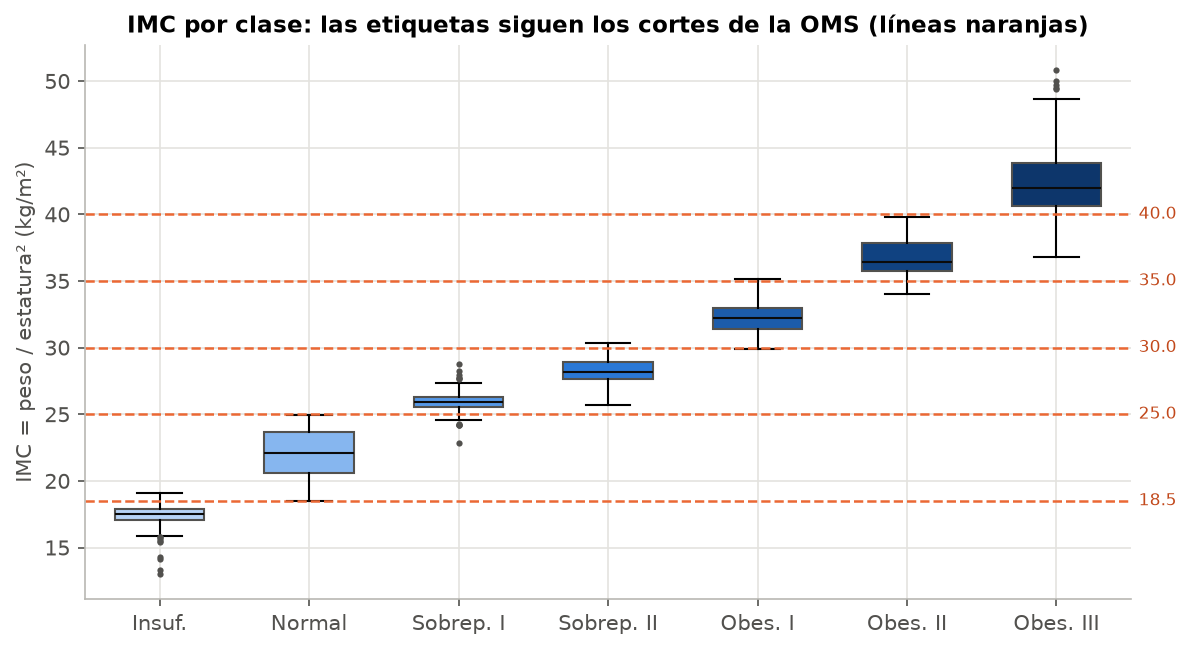

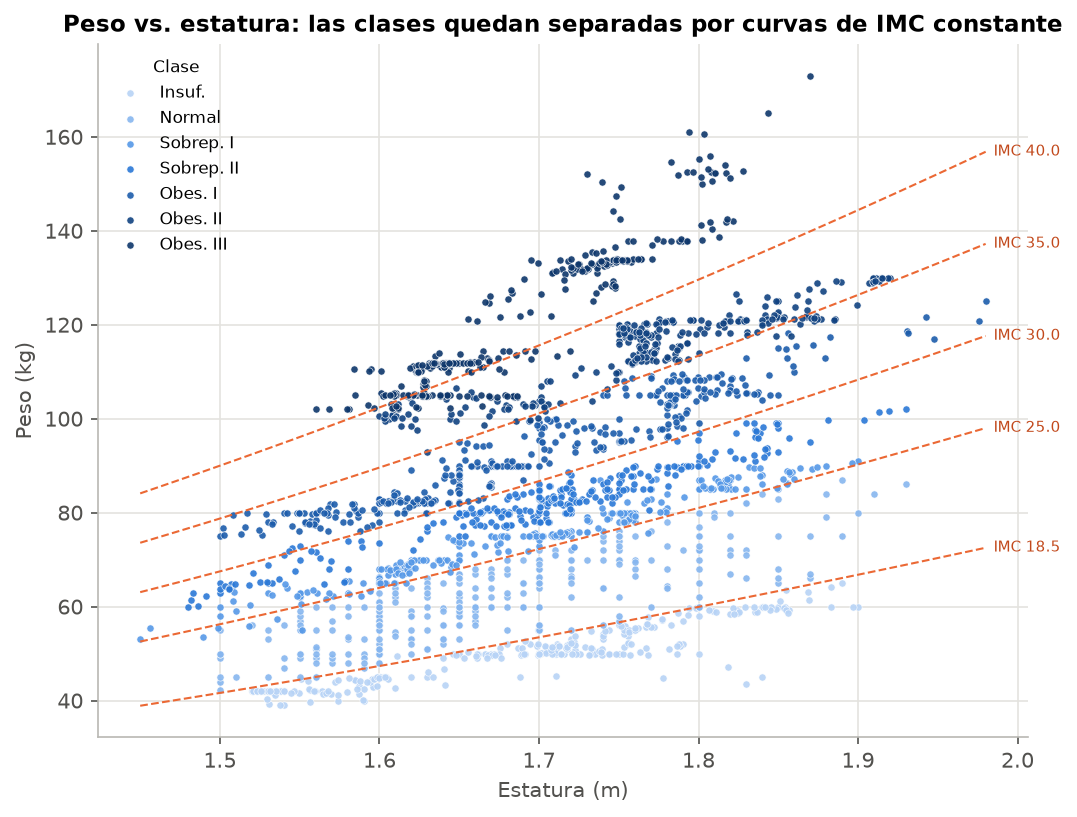

In [16]:
leakage.plot_bmi_by_class(df); show("07_imc_por_clase.png", 750)
leakage.plot_weight_height(df); show("08_peso_estatura_clases.png", 650)

Los rangos de IMC de cada clase están ordenados y casi no se solapan, y el **95,1 %** de las etiquetas
coincide con la categoría OMS calculada a partir de peso y estatura (uniendo Sobrepeso I y II, que la OMS
no separa). En el plano peso–estatura las clases quedan separadas por las curvas $peso = IMC \cdot estatura^2$.

**Implicación:** con `Weight` y `Height` como predictores, el problema se reduce a recalcular una fórmula
conocida. El modelo obtendría un rendimiento muy alto, pero no aprendería nada sobre la relación entre
hábitos y obesidad. Además, quien conozca peso y estatura no necesita un modelo: basta con calcular el IMC.
Es una forma de **fuga de información del objetivo** (*target leakage*): los predictores contienen la
definición de la etiqueta.

En el notebook 02 se cuantifica este efecto comparando modelos con y sin estas variables.